# N-CMAPSS DS02 | Motor 5 hata analizi

Stride 256 Vanilla LSTM deneyinde motor 5 doğrulama için ayrılır. Bu notebook, ilk yedi uçuşta modelin kalan ömrü (RUL) düşük tahmin edip etmediğini ve bu uçuşların toplam hataya katkısını ölçer.

In [1]:
from pathlib import Path
import sys

cwd = Path.cwd()
relative_script = Path("models/LTSM/stride256_experiment.py")
for directory in (cwd, *cwd.parents):
    for candidate in (directory / relative_script, directory / "n_cmapss" / relative_script):
        if candidate.is_file():
            script = candidate
            break
    else:
        continue
    break
else:
    raise FileNotFoundError("stride256_experiment.py bulunamadı. Notebook'u proje içinde çalıştırın.")

sys.path.insert(0, str(script.parent))
from stride256_experiment import (
    BATCH_SIZE, DEV_UNITS, EPOCHS, LEARNING_RATE, OUTPUT_CSV,
    SEED, UNITS, DROPOUT, WINDOW_SIZE, build_vanilla_lstm,
    discover_windows, EarlyStopping, np, pd, StandardScaler, tf,
)

baseline = pd.read_csv(OUTPUT_CSV).set_index("validation_motor")
print(baseline[["val_mae", "val_rmse"]].round(2).to_string())

                  val_mae  val_rmse
validation_motor                   
2                    4.14      5.78
5                    7.49     10.10
10                   6.25      8.64
16                   3.99      5.44
18                   2.67      3.75
20                   6.71      8.45


## Motor 5 doğrulama katını yeniden çalıştır

Eğitim diğer beş geliştirme motoruyla yapılır. Ölçekleyiciler yalnızca eğitim verisiyle hesaplanır. Mevcut deneyi yeniden üretmek için en iyi epoch motor 5’in doğrulama kaybıyla seçilir. Bu nedenle sonuçlar bağımsız test skoru olarak yorumlanmamalıdır.

In [2]:
validation_motor = 5
X, y, window_units = discover_windows()

train_units = [unit for unit in DEV_UNITS if unit != validation_motor]
train_mask = np.isin(window_units, train_units)
val_mask = window_units == validation_motor

X_train = X[train_mask]
X_val = X[val_mask]
y_train = y[train_mask]
y_val = y[val_mask]

feature_scaler = StandardScaler()
n_features = X_train.shape[2]

X_train_scaled = feature_scaler.fit_transform(
    X_train.reshape(-1, n_features)
).reshape(X_train.shape).astype("float32")

X_val_scaled = feature_scaler.transform(
    X_val.reshape(-1, n_features)
).reshape(X_val.shape).astype("float32")

y_mean = float(y_train.mean())
y_std = float(y_train.std())
y_train_scaled = ((y_train - y_mean) / y_std).astype("float32")
y_val_scaled = ((y_val - y_mean) / y_std).astype("float32")

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

model = build_vanilla_lstm(
    units=UNITS,
    dropout=DROPOUT,
    window_size=WINDOW_SIZE,
    n_features=n_features,
)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse",
    metrics=["mae"],
)

history = model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
        )
    ],
    verbose=0,
)

pred_scaled = model.predict(X_val_scaled, verbose=0).ravel()
pred = pred_scaled * y_std + y_mean


print(f"Eğitimde en yüksek RUL = {y_train.max():.0f}")
print(f"Kayıtlı motor 5 RMSE = {baseline.loc[5, 'val_rmse']:.4f}")

Eğitimde en yüksek RUL = 81
Kayıtlı motor 5 RMSE = 10.0983


## İlk yedi uçuşun hataya katkısı

Eğitimdeki en yüksek RUL, motor 5’in ilk yedi uçuşunu diğer uçuşlardan ayırır. Negatif tahmin farkı, modelin kalan ömrü eksik tahmin ettiğini gösterir. Karşılaştırma boyunca model ve tahminler aynıdır.

In [3]:
windows = pd.DataFrame({"Gerçek RUL": y_val, "Tahmin": pred})
windows["Hata"] = windows["Tahmin"] - windows["Gerçek RUL"]
windows["Karesel hata"] = windows["Hata"] ** 2
initial = windows["Gerçek RUL"] > y_train.max()

rows = []
for label, group in [
    ("Tüm uçuşlar", windows),
    ("İlk yedi uçuş", windows[initial]),
    ("Kalan uçuşlar", windows[~initial]),
]:
    rows.append({
        "Bölüm": label,
        "Pencere": len(group),
        "RMSE": np.sqrt(group["Karesel hata"].mean()),
        "Ortalama hata": group["Hata"].mean(),
        "Eksik tahmin (%)": 100 * (group["Hata"] < 0).mean(),
        "Toplam karesel hata payı (%)": (
            100 * group["Karesel hata"].sum() / windows["Karesel hata"].sum()
        ),
    })

summary = pd.DataFrame(rows).set_index("Bölüm")
print(summary.round(2).to_string())
drop_pct = 100 * (1 - summary.loc["Kalan uçuşlar", "RMSE"] / summary.loc["Tüm uçuşlar", "RMSE"])
print(f"İlk yedi uçuş hariç RMSE düşüşü = %{drop_pct:.1f}")

               Pencere       RMSE  Ortalama hata  Eksik tahmin (%)  Toplam karesel hata payı (%)
Bölüm                                                                                           
Tüm uçuşlar       3990  10.100000      -6.780000             87.49                    100.000000
İlk yedi uçuş      277  23.209999     -22.790001            100.00                     36.669998
Kalan uçuşlar     3713   8.330000      -5.590000             86.56                     63.330002
İlk yedi uçuş hariç RMSE düşüşü = %17.5


In [4]:
# Bu motorda her uçuşun RUL değeri farklıdır ve her uçuşta bir azalır.
flights = windows.groupby("Gerçek RUL", as_index=False).agg(
    Tahmin=("Tahmin", "mean"), Pencere=("Tahmin", "size")
).sort_values("Gerçek RUL", ascending=False)
flights.insert(0, "Uçuş", (y_val.max() - flights["Gerçek RUL"] + 1).astype(int))
flights["Hata"] = flights["Tahmin"] - flights["Gerçek RUL"]
print(flights.head(7).round(2).to_string(index=False))

for label, group in [
    ("Tüm uçuşlar", flights),
    ("İlk yedi uçuş", flights[flights["Gerçek RUL"] > y_train.max()]),
    ("Kalan uçuşlar", flights[flights["Gerçek RUL"] <= y_train.max()]),
]:
    print(f"{label} | eşit uçuş ağırlıklı RMSE = {np.sqrt((group['Hata'] ** 2).mean()):.2f}")

 Uçuş  Gerçek RUL    Tahmin  Pencere       Hata
    1        88.0 63.750000       48 -24.250000
    2        87.0 63.680000       55 -23.320000
    3        86.0 60.779999       34 -25.219999
    4        85.0 60.939999       27 -24.059999
    5        84.0 63.230000       48 -20.770000
    6        83.0 63.299999       34 -19.700001
    7        82.0 59.680000       31 -22.320000
Tüm uçuşlar | eşit uçuş ağırlıklı RMSE = 9.54
İlk yedi uçuş | eşit uçuş ağırlıklı RMSE = 22.88
Kalan uçuşlar | eşit uçuş ağırlıklı RMSE = 7.36


İlk yedi uçuş, pencerelerin yaklaşık %7’sini ve toplam karesel hatanın yaklaşık %37’sini oluşturuyor. Bu uçuşlar çıkarıldığında pencere bazlı RMSE 10,10’dan 8,33’e düşüyor. Kalan uçuşlarda da model ortalama 5,59 uçuş eksik tahmin ediyor. Bu karşılaştırma hatanın yoğunlaştığı bölümü gösteriyor. RUL aralığının etkisini bozulma hızının etkisinden ayırmak için ek deney gerekiyor.

## Temel ayar: stride 1024
Aynı Vanilla LSTM ayarlarıyla kayıtlı metrikler karşılaştırılır. İlk yedi uçuş analizi stride 1024 için tekrarlanır.

In [5]:
reference = pd.read_csv(OUTPUT_CSV.with_name("vanilla_cross_validation_results.csv"))
reference = reference.query("units == 32 and seed == 42 and dropout == 0.2 and batch_size == 64 and epochs == 50")
reference = reference.set_index("validation_motor")
metrics = ["val_mae", "val_rmse"]
comparison = pd.concat({"Stride 1024": reference[metrics], "Stride 256": baseline[metrics]}, axis=1)
comparison.loc["Motor ortalaması"] = comparison.mean()
print(comparison.to_string(float_format=lambda value: f"{value:.2f}"))

                 Stride 1024          Stride 256         
                     val_mae val_rmse    val_mae val_rmse
validation_motor                                         
2                       4.71     6.62       4.14     5.78
5                       6.46     9.40       7.49    10.10
10                      5.15     7.42       6.25     8.64
16                      3.93     5.70       3.99     5.44
18                      3.30     4.41       2.67     3.75
20                      4.95     6.14       6.71     8.45
Motor ortalaması        4.75     6.61       5.21     7.02


In [7]:
windows = pd.DataFrame({"Gerçek RUL": y_val, "Tahmin": pred})
windows["Hata"] = windows["Tahmin"] - windows["Gerçek RUL"]
windows["Karesel hata"] = windows["Hata"] ** 2
initial = windows["Gerçek RUL"] > y_train.max()

rows = []
for label, group in [
    ("Tüm uçuşlar", windows),
    ("İlk yedi uçuş", windows[initial]),
    ("Kalan uçuşlar", windows[~initial]),
]:
    rows.append({
        "Bölüm": label,
        "Pencere": len(group),
        "RMSE": np.sqrt(group["Karesel hata"].mean()),
        "Ortalama hata": group["Hata"].mean(),
        "Eksik tahmin (%)": 100 * (group["Hata"] < 0).mean(),
        "Toplam karesel hata payı (%)": (
            100 * group["Karesel hata"].sum() / windows["Karesel hata"].sum()
        ),
    })

summary = pd.DataFrame(rows).set_index("Bölüm")
print(summary.to_string(float_format=lambda value: f"{value:.2f}"))
drop_pct = 100 * (1 - summary.loc["Kalan uçuşlar", "RMSE"] / summary.loc["Tüm uçuşlar", "RMSE"])
print(f"İlk yedi uçuş hariç RMSE düşüşü = %{drop_pct:.1f}")

               Pencere  RMSE  Ortalama hata  Eksik tahmin (%)  Toplam karesel hata payı (%)
Bölüm                                                                                      
Tüm uçuşlar       1034  9.40          -5.73             80.56                        100.00
İlk yedi uçuş       71 23.74         -23.57            100.00                         43.82
Kalan uçuşlar      963  7.30          -4.41             79.13                         56.18
İlk yedi uçuş hariç RMSE düşüşü = %22.3


## Aynı uçuş numarasında HPT verim kaybı

Altı geliştirme motoru, her uçuşun ilk örneğindeki HPT verim parametresi kullanılarak karşılaştırılır. Başlangıç farkını gidermek için her motorun kaybı kendi ilk uçuşuna göre hesaplanır. Kesikli çizgiler HPT ile birlikte LPT de bozulan motorları gösterir. HPT parametresi bu analizde teşhis içindir.

Motor      2       5       10      16      18      20
Uçuş                                                 
17    0.00015 0.00053 0.00049 0.00020 0.00065 0.00022
30    0.00073 0.00074 0.00075 0.00065 0.00095 0.00066
40    0.00169 0.00126 0.00139 0.00178 0.00148 0.00170
50    0.00331 0.00218 0.00274 0.00361 0.00278 0.00291
60    0.00685 0.00365 0.00481 0.00688 0.00456 0.00510
30–60. uçuş arasında ilave HPT kaybı
Motor
2    0.00612
5    0.00292
10   0.00406
16   0.00623
18   0.00361
20   0.00444


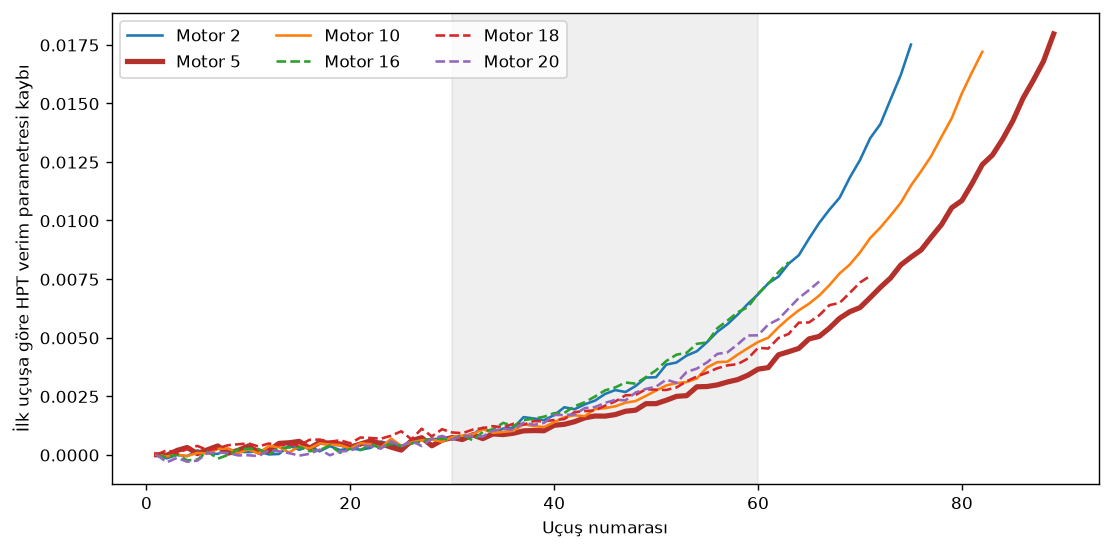

In [8]:
import h5py
import matplotlib.pyplot as plt
from stride256_experiment import DATA_PATH

with h5py.File(DATA_PATH, "r") as data:
    ids = data["A_dev"][:, :2].astype(int)
    starts = np.r_[0, np.flatnonzero(np.any(ids[1:] != ids[:-1], axis=1)) + 1]
    hpt_column = list(data["T_var"][:]).index(b"HPT_eff_mod")
    hpt = pd.DataFrame({
        "Motor": ids[starts, 0],
        "Uçuş": ids[starts, 1],
        "HPT": data["T_dev"][starts, hpt_column],
    }).sort_values(["Motor", "Uçuş"])

hpt["HPT kaybı"] = hpt.groupby("Motor")["HPT"].transform("first") - hpt["HPT"]
same_flight = hpt.pivot(index="Uçuş", columns="Motor", values="HPT kaybı")
print(same_flight.loc[[17, 30, 40, 50, 60]].to_string(float_format=lambda x: f"{x:.5f}"))
print("30–60. uçuş arasında ilave HPT kaybı")
print((same_flight.loc[60] - same_flight.loc[30]).to_string(float_format=lambda x: f"{x:.5f}"))

fig, ax = plt.subplots(figsize=(9, 4.5))
for motor in same_flight:
    values = same_flight[motor].dropna()
    ax.plot(values.index, values, label=f"Motor {motor}",
            color="#b4302b" if motor == 5 else None,
            linewidth=3 if motor == 5 else 1.5,
            linestyle="--" if motor in (16, 18, 20) else "-")
ax.axvspan(30, 60, color="gray", alpha=0.12)
ax.set(xlabel="Uçuş numarası", ylabel="İlk uçuşa göre HPT verim parametresi kaybı")
ax.legend(ncol=3)
fig.tight_layout()
plt.show()

## Aynı doğrulama pencerelerinde eğitim stride karşılaştırması

Pencere boyutu 256 ve seed 42 sabit. Eğitim stride değerleri 256, 512 ve 1024. Motor 5 eğitim dışında tutulur. Üç model için aynı stride 1024 doğrulama pencereleri kullanılır. Bu pencereler mevcut deneyle uyumlu olarak epoch seçiminde de kullanıldığı için skorlar doğrulama skorudur.

In [9]:
import stride256_experiment as experiment

def windows_at_stride(stride):
    original_stride = experiment.STRIDE
    try:
        experiment.STRIDE = stride
        return discover_windows()
    finally:
        experiment.STRIDE = original_stride

validation_motor = 5
validation_stride = 1024
X, y, window_units = windows_at_stride(validation_stride)
held_out = window_units == validation_motor
common_X, common_y = X[held_out], y[held_out]
del X, y, window_units

rows = []
validation_predictions = {}
for stride in (256, 512, 1024):
    X, y, window_units = windows_at_stride(stride)
    train_units = [unit for unit in DEV_UNITS if unit != validation_motor]
    train_mask = np.isin(window_units, train_units)

    X_train = X[train_mask]
    X_val = common_X
    y_train = y[train_mask]
    y_val = common_y

    feature_scaler = StandardScaler()
    n_features = X_train.shape[2]

    X_train_scaled = feature_scaler.fit_transform(
        X_train.reshape(-1, n_features)
    ).reshape(X_train.shape).astype("float32")

    X_val_scaled = feature_scaler.transform(
        X_val.reshape(-1, n_features)
    ).reshape(X_val.shape).astype("float32")

    y_mean = float(y_train.mean())
    y_std = float(y_train.std())
    y_train_scaled = ((y_train - y_mean) / y_std).astype("float32")
    y_val_scaled = ((y_val - y_mean) / y_std).astype("float32")

    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    model = build_vanilla_lstm(
        units=UNITS,
        dropout=DROPOUT,
        window_size=WINDOW_SIZE,
        n_features=n_features,
    )
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
        loss="mse",
        metrics=["mae"],
    )

    history = model.fit(
        X_train_scaled,
        y_train_scaled,
        validation_data=(X_val_scaled, y_val_scaled),
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[
            EarlyStopping(
                monitor="val_loss",
                patience=5,
                restore_best_weights=True,
            )
        ],
        verbose=0,
    )

    pred_scaled = model.predict(X_val_scaled, verbose=0).ravel()
    pred = pred_scaled * y_std + y_mean

    validation_predictions[stride] = pred.copy()

    for section, mask in [
        ("Tüm uçuşlar", np.ones(len(y_val), dtype=bool)),
        ("İlk 7 uçuş", y_val > y_train.max()),
        ("Kalan uçuşlar", y_val <= y_train.max()),
    ]:
        error = pred[mask] - y_val[mask]
        rows.append({
            "Eğitim stride": stride,
            "Bölüm": section,
            "Eğitim penceresi": len(y_train),
            "Doğrulama penceresi": mask.sum(),
            "En iyi epoch": int(np.argmin(history.history["val_loss"])) + 1,
            "MAE": np.abs(error).mean(),
            "RMSE": np.sqrt(np.mean(error ** 2)),
            "Ortalama hata": error.mean(),
        })
    del X, y, window_units, X_train, X_train_scaled, X_val_scaled, model, history

stride_results = pd.DataFrame(rows)
assert stride_results.groupby("Bölüm")["Doğrulama penceresi"].nunique().eq(1).all()
print(stride_results.to_string(index=False, float_format=lambda x: f"{x:.2f}"))

 Eğitim stride         Bölüm  Eğitim penceresi  Doğrulama penceresi  En iyi epoch   MAE  RMSE  Ortalama hata
           256   Tüm uçuşlar             16349                 1034             4  7.61 10.34          -6.92
           256    İlk 7 uçuş             16349                   71             4 23.19 23.74         -23.19
           256 Kalan uçuşlar             16349                  963             4  6.46  8.56          -5.73
           512   Tüm uçuşlar              8273                 1034            15  6.11  9.00          -5.39
           512    İlk 7 uçuş              8273                   71            15 23.22 23.34         -23.22
           512 Kalan uçuşlar              8273                  963            15  4.84  6.85          -4.08
          1024   Tüm uçuşlar              4236                 1034            19  6.46  9.40          -5.73
          1024    İlk 7 uçuş              4236                   71            19 23.57 23.74         -23.57
          1024 Kala

Motor 5, 30–60. uçuşlar arasında aynı arıza modundaki motor 2 ve 10’dan daha az HPT verimi kaybetti. Ortak pencerelerde en düşük genel MAE stride **512** ile elde edildi. HPT eğrisi bu hata farkının nedenini tek başına belirlemez.

## Uçuş süresi ve RMSE ağırlığı

Ortak doğrulama pencerelerindeki tahminler yeniden kullanılır. Pencere bazlı RMSE her pencereye eşit ağırlık verir. Eşit uçuş ağırlıklı RMSE her uçuşun ortalama karesel hatasını alır ve bu değerleri uçuşlar arasında eşit ağırlıkla birleştirir. Uçuş başına tek tahminle RMSE ise her uçuşun pencere tahminlerini önce ortalar. İlk iki ölçüm arasındaki fark ağırlık etkisini, son iki ölçüm arasındaki fark ise tahminleri ortalamanın etkisini gösterir.

 Eğitim stride              Bölüm  Pencere RMSE  Eşit uçuş ağırlıklı RMSE  Uçuş başına tek tahmin RMSE
           256        Tüm uçuşlar        10.345                    10.534                        9.749
           256         İlk 7 uçuş        23.739                    23.874                       23.329
           256 8. uçuş ve sonrası         8.565                     8.473                        7.530
           512        Tüm uçuşlar         9.003                     9.220                        8.929
           512         İlk 7 uçuş        23.335                    23.353                       23.291
           512 8. uçuş ve sonrası         6.847                     6.761                        6.342
          1024        Tüm uçuşlar         9.397                     9.677                        9.341
          1024         İlk 7 uçuş        23.738                    23.972                       23.880
          1024 8. uçuş ve sonrası         7.298                     7.251

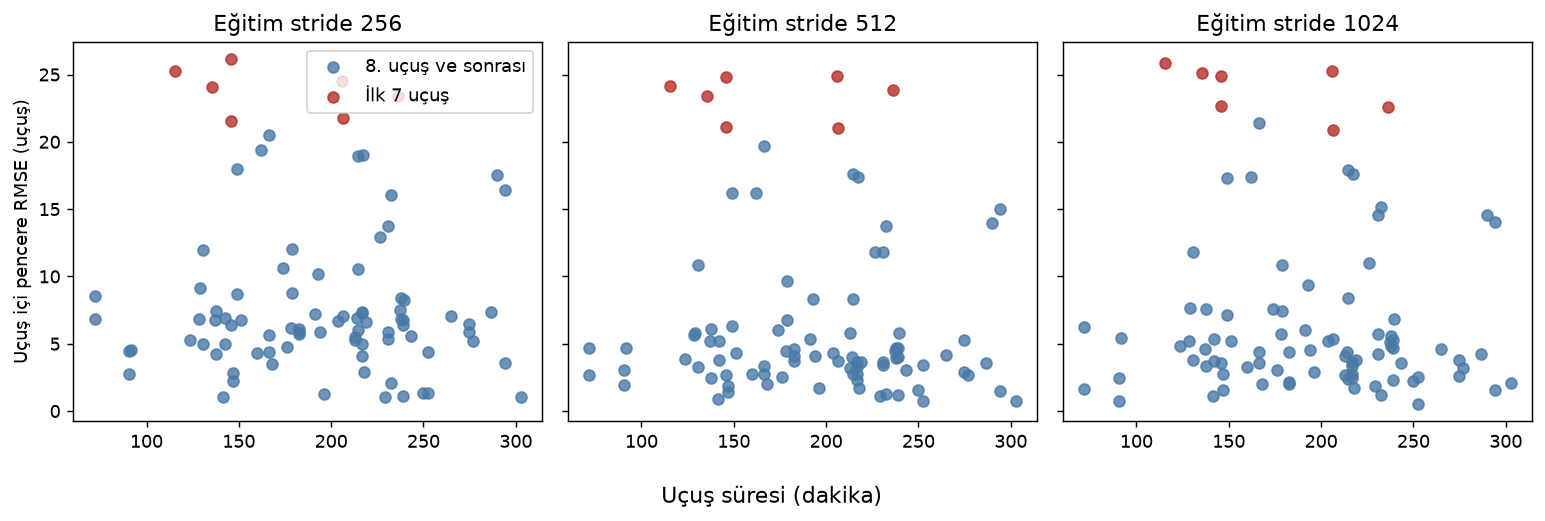

In [10]:
import h5py
import matplotlib.pyplot as plt
from stride256_experiment import DATA_PATH

with h5py.File(DATA_PATH, "r") as data:
    flight_ids = data["A_dev"][:, :2].astype(int)
    motor5_cycles = flight_ids[flight_ids[:, 0] == 5, 1]
flight_duration = pd.Series(motor5_cycles).value_counts().sort_index().rename("Süre (sn)")

weight_rows = []
fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True, sharey=True)
for ax, (stride, predictions) in zip(axes, validation_predictions.items()):
    errors = predictions.astype(float) - common_y
    # Motor 5'in RUL etiketi her uçuş sonunda bir azalır.
    cycles = (common_y.max() - common_y + 1).astype(int)
    windows = pd.DataFrame({"Uçuş": cycles, "Hata": errors, "Hata karesi": errors ** 2})
    flights = windows.groupby("Uçuş").agg(
        mse=("Hata karesi", "mean"), mean_error=("Hata", "mean"), count=("Hata", "size")
    ).join(flight_duration)
    assert flights.index.equals(flight_duration.index)
    assert np.array_equal(flights["count"], 1 + (flights["Süre (sn)"] - WINDOW_SIZE) // validation_stride)

    for label, group in [
        ("Tüm uçuşlar", flights),
        ("İlk 7 uçuş", flights.loc[:7]),
        ("8. uçuş ve sonrası", flights.loc[8:]),
    ]:
        weight_rows.append({
            "Eğitim stride": stride,
            "Bölüm": label,
            "Pencere RMSE": np.sqrt(np.average(group["mse"], weights=group["count"])),
            "Eşit uçuş ağırlıklı RMSE": np.sqrt(group["mse"].mean()),
            "Uçuş başına tek tahmin RMSE": np.sqrt((group["mean_error"] ** 2).mean()),
        })
    for label, group, color in [
        ("8. uçuş ve sonrası", flights.loc[8:], "#4879a6"),
        ("İlk 7 uçuş", flights.loc[:7], "#b4302b"),
    ]:
        ax.scatter(group["Süre (sn)"] / 60, np.sqrt(group["mse"]), label=label, color=color, alpha=0.8)
    ax.set_title(f"Eğitim stride {stride}")

axes[0].legend()
axes[0].set_ylabel("Uçuş içi pencere RMSE (uçuş)")
fig.supxlabel("Uçuş süresi (dakika)")
fig.tight_layout()
flight_weight_results = pd.DataFrame(weight_rows)
print(flight_weight_results.to_string(index=False, float_format=lambda value: f"{value:.3f}"))
plt.show()

Uçuşları eşit ağırlıklandırınca genel RMSE, stride 256, 512 ve 1024 için sırasıyla **-0.19**, **-0.22** ve **-0.28** uçuş değişiyor (pencere RMSE eksi eşit ağırlıklı RMSE). Sonuçlar motor 5’in ortak doğrulama pencerelerine ve seed 42’ye ait.


Bu notebook’ta pencere bazlı RMSE projenin mevcut değerlendirmesidir. Eşit uçuş ağırlıklı RMSE, uzun uçuşların pencere sayısından gelen ağırlık etkisini ölçmek için eklendi. Uçuş başına tek tahminli RMSE ise her uçuşun pencere tahminlerini ortalayan bu notebook’a özgü uygulamadır. Üç hesapta da aynı model tahminleri kullanılır.


## Benzer HPT kaybında kalan ömür

Motor 2, 5 ve 10 için ilk uçuşa göre hesaplanan HPT verim kaybının beş ortak eşiği incelenir. Her motor için eşiğin ilk aşıldığı uçuş seçilir. Motor 5’in tahmini, eğitim stride 512 modelinin ortak stride 1024 doğrulama pencerelerindeki uçuş ortalamasıdır.

In [11]:
import h5py
from stride256_experiment import DATA_PATH

with h5py.File(DATA_PATH, "r") as data:
    ids = data["A_dev"][:, :2].astype(int)
    starts = np.r_[0, np.flatnonzero(np.any(ids[1:] != ids[:-1], axis=1)) + 1]
    ends = np.r_[starts[1:], len(ids)]
    hpt_column = list(data["T_var"][:]).index(b"HPT_eff_mod")
    flight_data = pd.DataFrame({
        "Motor": ids[starts, 0],
        "Uçuş": ids[starts, 1],
        "Gerçek RUL": data["Y_dev"][starts, 0],
        "HPT": data["T_dev"][starts, hpt_column],
    })

flight_data["HPT kaybı"] = flight_data.groupby("Motor")["HPT"].transform("first") - flight_data["HPT"]
matched = []
for level in (0.002, 0.003, 0.004, 0.005, 0.006):
    crossed = flight_data[flight_data["Motor"].isin([2, 5, 10]) & (flight_data["HPT kaybı"] >= level)]
    matched.append(crossed.groupby("Motor").head(1).assign(Eşik=level))
matched = pd.concat(matched, ignore_index=True)
assert matched.groupby("Eşik")["Motor"].nunique().eq(3).all()
print(matched[["Eşik", "Motor", "Uçuş", "HPT kaybı", "Gerçek RUL"]].to_string(index=False))

 Eşik  Motor  Uçuş  HPT kaybı  Gerçek RUL
0.002      2    41   0.002027          34
0.002      5    49   0.002180          40
0.002     10    46   0.002069          36
0.003      2    49   0.003292          26
0.003      5    57   0.003107          32
0.003     10    52   0.003060          30
0.004      2    53   0.004235          22
0.004      5    62   0.004266          27
0.004     10    58   0.004275          24
0.005      2    56   0.005249          19
0.005      5    66   0.005051          23
0.005     10    62   0.005437          20
0.006      2    59   0.006440          16
0.006      5    69   0.006105          20
0.006     10    64   0.006166          18


In [12]:
import stride256_experiment as experiment

def windows_at_stride(stride):
    original_stride = experiment.STRIDE
    try:
        experiment.STRIDE = stride
        return discover_windows()
    finally:
        experiment.STRIDE = original_stride

validation_motor = 5
validation_stride = 1024
X, y, window_units = windows_at_stride(validation_stride)
held_out = window_units == validation_motor
common_X, common_y = X[held_out], y[held_out]
del X, y, window_units

stride = 512
X, y, window_units = windows_at_stride(stride)
train_units = [unit for unit in DEV_UNITS if unit != validation_motor]
train_mask = np.isin(window_units, train_units)

X_train = X[train_mask]
X_val = common_X
y_train = y[train_mask]
y_val = common_y

feature_scaler = StandardScaler()
n_features = X_train.shape[2]

X_train_scaled = feature_scaler.fit_transform(
    X_train.reshape(-1, n_features)
).reshape(X_train.shape).astype("float32")

X_val_scaled = feature_scaler.transform(
    X_val.reshape(-1, n_features)
).reshape(X_val.shape).astype("float32")

y_mean = float(y_train.mean())
y_std = float(y_train.std())
y_train_scaled = ((y_train - y_mean) / y_std).astype("float32")
y_val_scaled = ((y_val - y_mean) / y_std).astype("float32")

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(SEED)

model = build_vanilla_lstm(
    units=UNITS,
    dropout=DROPOUT,
    window_size=WINDOW_SIZE,
    n_features=n_features,
)
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=LEARNING_RATE),
    loss="mse",
    metrics=["mae"],
)

history = model.fit(
    X_train_scaled,
    y_train_scaled,
    validation_data=(X_val_scaled, y_val_scaled),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[
        EarlyStopping(
            monitor="val_loss",
            patience=5,
            restore_best_weights=True,
        )
    ],
    verbose=0,
)

pred_scaled = model.predict(X_val_scaled, verbose=0).ravel()
pred = pred_scaled * y_std + y_mean


motor5_predictions = pd.DataFrame({"Gerçek RUL": common_y, "Motor 5 tahmini": pred})
motor5_predictions = motor5_predictions.groupby("Gerçek RUL")["Motor 5 tahmini"].mean()
match_table = matched.pivot(index="Eşik", columns="Motor", values="Gerçek RUL")
match_table.columns = ["Motor 2 gerçek RUL", "Motor 5 gerçek RUL", "Motor 10 gerçek RUL"]
match_table["Motor 5 tahmini"] = match_table["Motor 5 gerçek RUL"].map(motor5_predictions)
match_table["Motor 5 hata"] = match_table["Motor 5 tahmini"] - match_table["Motor 5 gerçek RUL"]
assert match_table["Motor 5 tahmini"].notna().all()
print(match_table.to_string(float_format=lambda value: f"{value:.2f}"))
del X, y, window_units, X_train, X_train_scaled, X_val_scaled, X_val, common_X, model

       Motor 2 gerçek RUL  Motor 5 gerçek RUL  Motor 10 gerçek RUL  Motor 5 tahmini  Motor 5 hata
Eşik                                                                                             
0.002                  34                  40                   36            34.78         -5.22
0.003                  26                  32                   30            26.97         -5.03
0.004                  22                  27                   24            23.28         -3.72
0.005                  19                  23                   20            20.61         -2.39
0.006                  16                  20                   18            17.07         -2.93


## Uçuş geçmişi eklenince hata değişiyor mu?

İki Ridge modeli aynı uçuşları kullanır. Tek uçuş modeli 18 kanalın ortalama ve standart sapmasını görür. Son beş uçuş modeli bu özete önceki dört uçuşa göre farkları ekler. HPT parametresi model girdisi değildir. Ölçekleme yalnızca eğitimde öğrenilir ve her iki modelde alpha=10 kullanılır.

In [13]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline

with h5py.File(DATA_PATH, "r") as data:
    summaries = []
    for start, end in zip(starts, ends):
        channels = np.column_stack((data["W_dev"][start:end], data["X_s_dev"][start:end]))
        summaries.append(np.r_[channels.mean(axis=0), channels.std(axis=0)])

current = pd.DataFrame(summaries, index=flight_data.index)
by_motor = current.groupby(flight_data["Motor"], sort=False)
history_features = pd.concat(
    [current] + [current - by_motor.shift(lag) for lag in range(1, 5)],
    axis=1, ignore_index=True,
)
eligible = history_features.notna().all(axis=1)
train = eligible & flight_data["Motor"].isin([2, 10, 16, 18, 20])
val = eligible & flight_data["Motor"].eq(5)
target = flight_data["Gerçek RUL"]
predictions = flight_data.loc[val, ["Uçuş", "Gerçek RUL"]].copy()
rows = []
for name, features in [("Tek uçuş", current), ("Son 5 uçuş", history_features)]:
    model = make_pipeline(StandardScaler(), Ridge(alpha=10))
    model.fit(features.loc[train], target.loc[train])
    predictions[name] = model.predict(features.loc[val])
    for section, mask in [
        ("Tüm ortak uçuşlar", val),
        ("8. uçuş ve sonrası", val & flight_data["Uçuş"].ge(8)),
        ("30–60. uçuşlar", val & flight_data["Uçuş"].between(30, 60)),
    ]:
        error = predictions.loc[mask, name] - target.loc[mask]
        rows.append({
            "Model": name, "Bölüm": section, "Uçuş": len(error),
            "MAE": error.abs().mean(), "RMSE": np.sqrt((error ** 2).mean()),
            "Ortalama hata": error.mean(),
        })
history_results = pd.DataFrame(rows)
print(history_results.to_string(index=False, float_format=lambda value: f"{value:.2f}"))

     Model              Bölüm  Uçuş   MAE  RMSE  Ortalama hata
  Tek uçuş  Tüm ortak uçuşlar    85 11.57 15.54          -8.15
  Tek uçuş 8. uçuş ve sonrası    82 10.63 14.13          -7.09
  Tek uçuş     30–60. uçuşlar    31  5.24  6.55          -2.67
Son 5 uçuş  Tüm ortak uçuşlar    85 12.09 16.27          -8.60
Son 5 uçuş 8. uçuş ve sonrası    82 11.10 14.76          -7.48
Son 5 uçuş     30–60. uçuşlar    31  6.06  7.75          -3.28


### HPT incelemesinin sonucu

Beş eşikte de motor 5’in gerçek RUL’u motor 2 ve 10’dan yüksekti. LSTM motor 5’in RUL’unu 2,39–5,22 uçuş eksik tahmin etti. Bu örüntü HPT hipoteziyle uyumlu, ancak eşikler aynı motorun bozulma eğrisinden geliyor. Son beş uçuşun geçmişi Ridge modelinin ortak 85 uçuşta RMSE’sini 15,54’ten 16,27’ye çıkardı.

## Motor 5 için iyileştirme deneyleri

DS02’nin altı geliştirme motorunda her motor sırayla dışarıda bırakılır. Uçuş bazlı Ridge deneyinde çalışma koşullarının sensörlere etkisi, yalnız eğitim motorlarının sağlıklı örnekleriyle öğrenilir. Aynı 85 motor 5 uçuşunda ham özet, koşul düzeltilmiş özet ve geçmiş farkları karşılaştırılır. Ayrıca stride 512 LSTM’de yüksek RUL örneklerine ağırlık vermenin etkisi aynı doğrulama pencerelerinde sınanır.

In [14]:
import h5py
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
from stride256_experiment import DATA_PATH

with h5py.File(DATA_PATH, "r") as data:
    info = data["A_dev"][:].astype(int)
    starts = np.r_[0, np.flatnonzero(np.any(info[1:, :2] != info[:-1, :2], axis=1)) + 1]
    ends = np.r_[starts[1:], len(info)]
    units = info[starts, 0]
    cycles = info[starts, 1]
    target = data["Y_dev"][starts, 0]
    conditions = data["W_dev"][:].astype("float32")
    sensors = data["X_s_dev"][:].astype("float32")

def flight_summary(values):
    return np.asarray([np.r_[values[start:end].mean(axis=0), values[start:end].std(axis=0)]
                       for start, end in zip(starts, ends)])

raw = np.column_stack((flight_summary(conditions), flight_summary(sensors)))
healthy = np.flatnonzero(info[:, 3] == 1)[::16]
records = []
for held_out in DEV_UNITS:
    reference = healthy[info[healthy, 0] != held_out]
    operating_model = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias=False), Ridge(alpha=10))
    operating_model.fit(conditions[reference], sensors[reference])
    residual = np.empty_like(sensors)
    for start in range(0, len(sensors), 100_000):
        batch = slice(start, start + 100_000)
        residual[batch] = sensors[batch] - operating_model.predict(conditions[batch])

    adjusted = np.column_stack((flight_summary(conditions), flight_summary(residual)))
    adjusted_frame = pd.DataFrame(adjusted)
    motor_groups = adjusted_frame.groupby(units, sort=False)
    trends = [adjusted_frame - motor_groups.shift(lag) for lag in range(1, 5)]
    history = np.column_stack([adjusted, *trends])
    eligible = np.isfinite(history).all(axis=1)
    train = eligible & (units != held_out)
    val = eligible & (units == held_out)
    assert (cycles[val] >= 5).all()

    for label, features in [
        ("Ham özet", raw),
        ("Koşul düzeltilmiş", adjusted),
        ("Koşul düzeltilmiş + geçmiş", history),
    ]:
        regressor = make_pipeline(StandardScaler(), Ridge(alpha=10))
        regressor.fit(features[train], target[train])
        errors = regressor.predict(features[val]) - target[val]
        for section, mask in [
            ("Tümü", np.ones(len(errors), dtype=bool)),
            ("30–60", (cycles[val] >= 30) & (cycles[val] <= 60)),
        ]:
            error = errors[mask]
            records.append(dict(Motor=held_out, Model=label, Bölüm=section,
                                MAE=np.abs(error).mean(), RMSE=np.sqrt(np.mean(error ** 2)),
                                Sapma=error.mean()))

flight_config_results = pd.DataFrame(records)
print(flight_config_results.query("Motor == 5").round(2).to_string(index=False))
print("Altı motorun ortalaması, tüm ortak uçuşlar")
print(flight_config_results.query("Bölüm == 'Tümü'").groupby("Model")[["MAE", "RMSE"]].mean().round(2).to_string())
del conditions, sensors, residual, info

 Motor                      Model Bölüm   MAE  RMSE  Sapma
     5                   Ham özet  Tümü 11.57 15.55  -8.16
     5                   Ham özet 30–60  5.24  6.55  -2.66
     5          Koşul düzeltilmiş  Tümü 10.56 14.51  -8.06
     5          Koşul düzeltilmiş 30–60  4.61  5.97  -2.08
     5 Koşul düzeltilmiş + geçmiş  Tümü 10.27 14.30  -8.29
     5 Koşul düzeltilmiş + geçmiş 30–60  5.15  6.34  -3.17
Altı motorun ortalaması, tüm ortak uçuşlar
                             MAE   RMSE
Model                                  
Ham özet                    9.43  11.30
Koşul düzeltilmiş           8.81  10.77
Koşul düzeltilmiş + geçmiş  8.78  10.80


## LSTM’de çalışma koşullarına göre sensör düzeltmesi

Her katta bir geliştirme motoru eğitim dışında tutulur. Sağlıklı eğitim örneklerinde irtifa, Mach, gaz kolu açısı ve giriş sıcaklığından beklenen sensör değerleri öğrenilir. Düzeltilmiş modelde ölçülen sensör değerlerinden beklenen değerler çıkarılır. Dört çalışma koşulu her iki modelin girdisinde korunur. Eğitim stride’ı 512, doğrulama stride’ı 1024, pencere boyutu 256 ve seed 42. İki koşul aynı doğrulama pencerelerinde değerlendirilir. Önceki deneyle uyumlu olarak bu pencereler epoch seçiminde de kullanılır.


In [15]:
import h5py
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures
import stride256_experiment as experiment

def load_windows(stride):
    original_stride = experiment.STRIDE
    try:
        experiment.STRIDE = stride
        return experiment.discover_windows()
    finally:
        experiment.STRIDE = original_stride

X_train_pool, train_rul, train_units = load_windows(512)
X_val_pool, val_rul, val_units = load_windows(1024)

with h5py.File(experiment.DATA_PATH, "r") as data:
    auxiliary = data["A_dev"][:].astype(int)
    healthy_rows = np.flatnonzero(auxiliary[:, 3] == 1)[::16]
    healthy_units = auxiliary[healthy_rows, 0]
    healthy_conditions = data["W_dev"][:][healthy_rows].astype("float32")
    healthy_sensors = data["X_s_dev"][:][healthy_rows].astype("float32")
del auxiliary

def correct_sensors(windows, healthy_model):
    result = windows.copy()
    rows = result.reshape(-1, result.shape[-1])
    n_conditions = healthy_conditions.shape[1]
    for start in range(0, len(rows), 100_000):
        batch = rows[start:start + 100_000]
        batch[:, n_conditions:] -= healthy_model.predict(batch[:, :n_conditions])
    return result

results = []
for unit in experiment.DEV_UNITS:
    train_mask = train_units != unit
    val_mask = val_units == unit
    y_train = train_rul[train_mask]
    y_val = val_rul[val_mask]
    y_mean, y_std = float(y_train.mean()), float(y_train.std())
    y_train_scaled = (y_train - y_mean) / y_std
    y_val_scaled = (y_val - y_mean) / y_std

    healthy_mask = healthy_units != unit
    healthy_model = make_pipeline(
        StandardScaler(), PolynomialFeatures(2, include_bias=False), Ridge(alpha=10)
    )
    healthy_model.fit(healthy_conditions[healthy_mask], healthy_sensors[healthy_mask])

    for treatment in ("Ham", "Düzeltilmiş"):
        X_train = X_train_pool[train_mask]
        X_val = X_val_pool[val_mask]
        if treatment == "Düzeltilmiş":
            X_train = correct_sensors(X_train, healthy_model)
            X_val = correct_sensors(X_val, healthy_model)
        n_features = X_train.shape[-1]
        scaler = StandardScaler(copy=False)
        X_train = scaler.fit_transform(X_train.reshape(-1, n_features)).reshape(X_train.shape)
        X_val = scaler.transform(X_val.reshape(-1, n_features)).reshape(X_val.shape)

        tf.keras.backend.clear_session()
        tf.keras.utils.set_random_seed(experiment.SEED)
        model = experiment.build_vanilla_lstm(
            units=experiment.UNITS, dropout=experiment.DROPOUT,
            window_size=experiment.WINDOW_SIZE, n_features=n_features,
        )
        model.compile(optimizer=tf.keras.optimizers.Adam(experiment.LEARNING_RATE), loss="mse")
        history = model.fit(
            X_train, y_train_scaled, validation_data=(X_val, y_val_scaled),
            epochs=experiment.EPOCHS, batch_size=experiment.BATCH_SIZE,
            callbacks=[experiment.EarlyStopping(patience=5, restore_best_weights=True)],
            verbose=0,
        )
        errors = model.predict(X_val, verbose=0).ravel() * y_std + y_mean - y_val
        groups = [("Tümü", np.ones(len(y_val), dtype=bool))]
        if unit == 5:
            groups += [("İlk 7 uçuş", y_val > y_train.max()), ("8. uçuş ve sonrası", y_val <= y_train.max())]
        for group, mask in groups:
            err = errors[mask]
            results.append({
                "Motor": unit, "Sensör": treatment, "Bölüm": group, "Pencere": mask.sum(),
                "MAE": np.abs(err).mean(), "RMSE": np.sqrt(np.mean(err ** 2)), "Sapma": err.mean(),
                "En iyi epoch": int(np.argmin(history.history["val_loss"])) + 1,
            })
        print(f"Motor {unit} | {treatment} | MAE {np.abs(errors).mean():.3f}", flush=True)
        del X_train, X_val, model, history

condition_lstm_results = pd.DataFrame(results)
all_flights = condition_lstm_results.query("Bölüm == 'Tümü'")
assert all_flights.groupby("Motor")["Pencere"].nunique().eq(1).all()
assert all_flights.groupby("Motor")["Sensör"].nunique().eq(2).all()
print("\nAltı motorun eşit ağırlıklı ortalaması")
print(all_flights.groupby("Sensör")[["MAE", "RMSE"]].mean().to_string(float_format=lambda v: f"{v:.3f}"))
print("\nMotor bazında sonuçlar")
print(condition_lstm_results.to_string(index=False, float_format=lambda v: f"{v:.3f}"))


Motor 2 | Ham | MAE 4.166
Motor 2 | Düzeltilmiş | MAE 5.169
Motor 5 | Ham | MAE 6.106
Motor 5 | Düzeltilmiş | MAE 7.497
Motor 10 | Ham | MAE 5.717
Motor 10 | Düzeltilmiş | MAE 5.691
Motor 16 | Ham | MAE 4.190
Motor 16 | Düzeltilmiş | MAE 4.536
Motor 18 | Ham | MAE 3.863
Motor 18 | Düzeltilmiş | MAE 3.021
Motor 20 | Ham | MAE 7.160
Motor 20 | Düzeltilmiş | MAE 6.934

Altı motorun eşit ağırlıklı ortalaması
              MAE  RMSE
Sensör                 
Düzeltilmiş 5.475 7.185
Ham         5.200 7.172

Motor bazında sonuçlar
 Motor      Sensör              Bölüm  Pencere    MAE   RMSE   Sapma  En iyi epoch
     2         Ham               Tümü      854  4.166  5.815   2.330            10
     2 Düzeltilmiş               Tümü      854  5.169  6.656   3.831             7
     5         Ham               Tümü     1034  6.106  9.003  -5.394            15
     5         Ham         İlk 7 uçuş       71 23.217 23.335 -23.217            15
     5         Ham 8. uçuş ve sonrası      963  4.844  6.

### Sensör düzeltmesi sonucu

Altı motorun ortalama MAE’si 5,200’den 5,475’e, ortalama RMSE’si 7,172’den 7,185’e yükseldi. Motor 5’in genel MAE’si 6,106’dan 7,497’ye, ilk yedi uçuş MAE’si 23,217’den 23,917’ye çıktı. Bu deneyde ham girdiler daha düşük ortalama MAE verdi. Sonuçlar seed 42 ve belirtilen doğrulama düzeni için geçerlidir.
